# Challenge 1: The banknote-authentication data set problem

We will perform a nearly realistic analysis of the data set bank note authentication that can be downloaded from this [link](https://archive.ics.uci.edu/dataset/267/banknote+authentication) or from the [github repo](https://github.com/LorenzoTonet/Intro_to_ML_26-27/blob/main/data/data_banknote_authentication.txt)

## Data set description

Data were extracted from images that were taken from genuine and forged banknote-like specimens. For digitization, an industrial camera usually used for print inspection was used. The final images have 400x 400 pixels. Due to the object lens and distance to the investigated object gray-scale pictures with a resolution of about 660 dpi were gained. Wavelet Transform tool were used to extract features from images.
These features are:
1. variance of Wavelet Transformed image (continuous) 
2. skewness of Wavelet Transformed image (continuous) 
3. curtosis of Wavelet Transformed image (continuous) 
4. entropy of image (continuous) 
5. class (integer)

## Task description
We have a binary classification problem. The assignment can be divided in several parts:
    
    1. Load the data and pretreatment.
    2. Data exploring by Unsupervised Learning techniques.
    3. Construction of several models of Supervised Learning.
    4. Assessment and evaluation

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk

### 1. Data pretreatment

Load the data and look at it: It is needed some kind of scaling? Why? Are the data points sorted in the original data set? Can it generate problems? How can this be solved?

In [45]:
path_csv = "../data/data_banknote_authentication.csv"
df = pd.read_csv(path_csv, header=None)
df.head()




,0,1,2,3,4
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [17]:
df.describe()

,0,1,2,3,4
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [22]:
df.shape; df.dtypes; df.head()
df.describe(include="all")


,0,1,2,3,4
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


DUplicati totali 24
Valori mancanti totali 0    0
1    0
2    0
3    0
4    0
dtype: int64


,0,1,2,3,4
0,1.000000,0.264026,-0.380850,0.276817,-0.724843
1,0.264026,1.000000,-0.786895,-0.526321,-0.444688
2,-0.380850,-0.786895,1.000000,0.318841,0.155883
3,0.276817,-0.526321,0.318841,1.000000,-0.023424
4,-0.724843,-0.444688,0.155883,-0.023424,1.000000


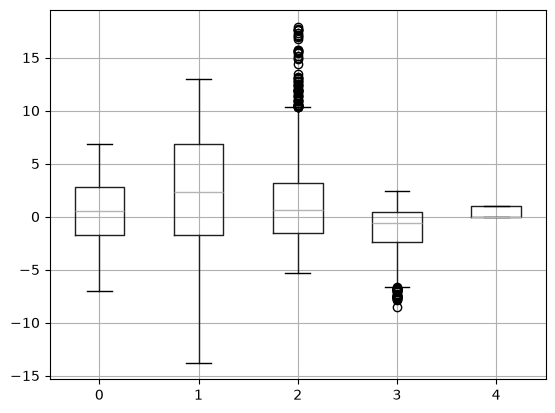

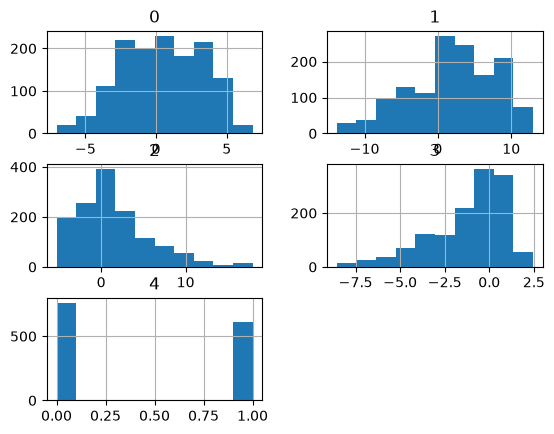

In [29]:
print("DUplicati totali", df.duplicated().sum())
print("Valori mancanti totali", df.isna().sum())
df.boxplot()                 # outlier
df.hist(); df.corr()

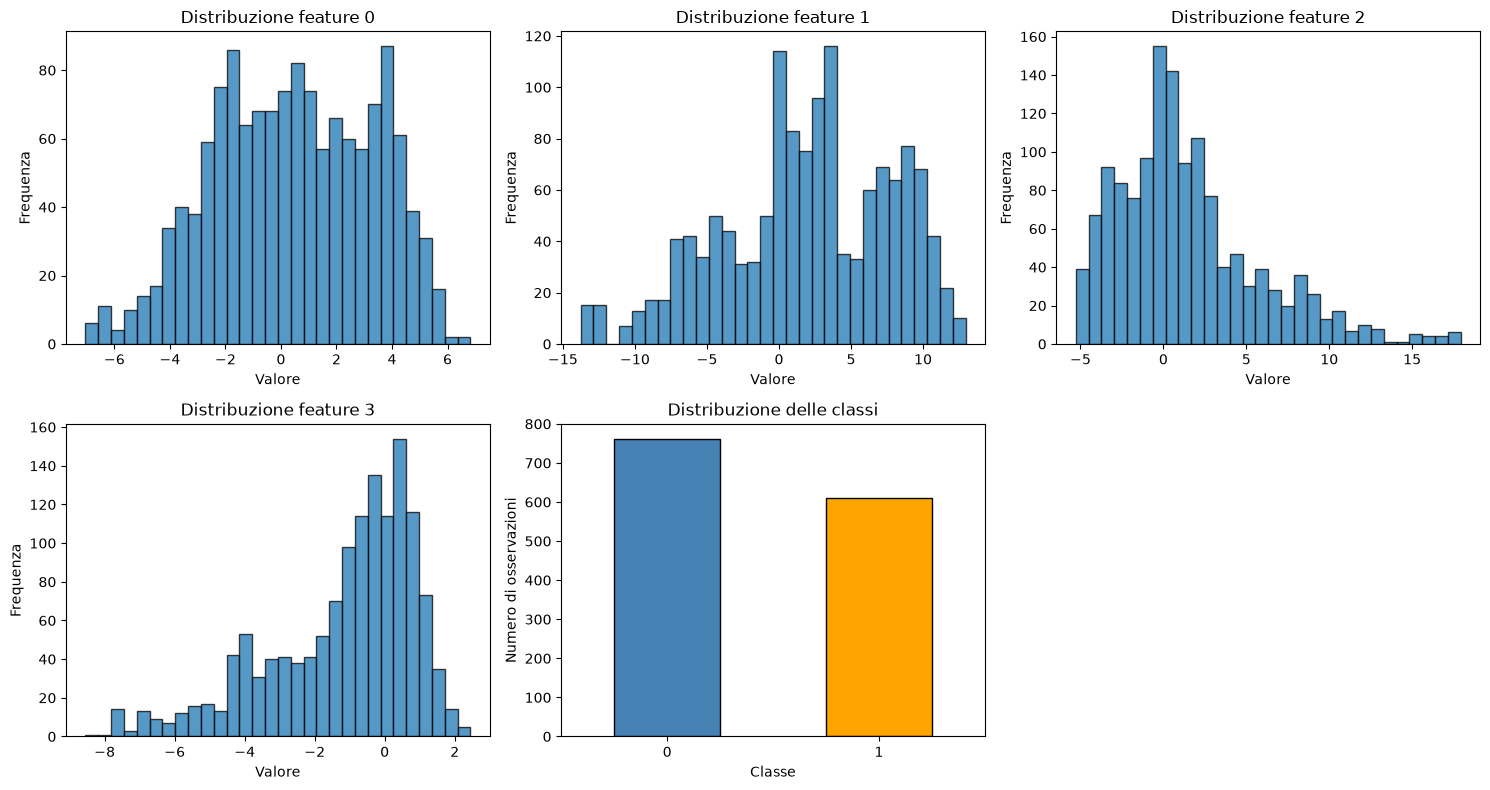

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Distribuzione delle quattro variabili numeriche
for i, col in enumerate(df.columns[:4]):
    axes.flat[i].hist(df[col], bins=30, edgecolor="black", alpha=0.75)
    axes.flat[i].set_title(f"Distribuzione feature {col}")
    axes.flat[i].set_xlabel("Valore")
    axes.flat[i].set_ylabel("Frequenza")

# Distribuzione delle classi
df[4].value_counts().sort_index().plot(
    kind="bar", ax=axes.flat[4], color=["steelblue", "orange"], edgecolor="black"
)
axes.flat[4].set_title("Distribuzione delle classi")
axes.flat[4].set_xlabel("Classe")
axes.flat[4].set_ylabel("Numero di osservazioni")
axes.flat[4].tick_params(axis="x", rotation=0)

axes.flat[5].axis("off")
plt.tight_layout()
plt.show()

In [31]:
features = df.iloc[:, :4]

Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (features < lower_bound) | (features > upper_bound)

print("Outlier per feature:")
print(outlier_mask.sum())

print("\nNumero di righe con almeno un outlier:")
print(outlier_mask.any(axis=1).sum())

print("\nPercentuale di righe con almeno un outlier:")
print(f"{outlier_mask.any(axis=1).mean() * 100:.2f}%")

# Controllo degli outlier separatamente per ciascuna classe
for classe, gruppo in df.groupby(4):
    classe_features = gruppo.iloc[:, :4]

    q1 = classe_features.quantile(0.25)
    q3 = classe_features.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (classe_features < lower) | (classe_features > upper)

    print(f"\nClasse {classe}:")
    print("Outlier per feature:")
    print(mask.sum())
    print("Righe con almeno un outlier:", mask.any(axis=1).sum())
    print(
        f"Percentuale di righe con almeno un outlier: "
        f"{mask.any(axis=1).mean() * 100:.2f}%"
    )
    totale_features = features.size
    totale_features_outlier = outlier_mask.sum().sum()

    print(f"Features totali: {totale_features}")
    print(f"Features outlier: {totale_features_outlier}")
    print(
        f"Percentuale di features outlier: "
        f"{totale_features_outlier / totale_features * 100:.2f}%"
    )

    print("\nOutlier per feature:")
    print(outlier_mask.sum())

Outlier per feature:
0     0
1     0
2    59
3    33
dtype: int64

Numero di righe con almeno un outlier:
92

Percentuale di righe con almeno un outlier:
6.71%

Classe 0:
Outlier per feature:
0     1
1     0
2     0
3    19
dtype: int64
Righe con almeno un outlier: 20
Percentuale di righe con almeno un outlier: 2.62%
Features totali: 5488
Features outlier: 92
Percentuale di features outlier: 1.68%

Outlier per feature:
0     0
1     0
2    59
3    33
dtype: int64

Classe 1:
Outlier per feature:
0     3
1     0
2    10
3    15
dtype: int64
Righe con almeno un outlier: 28
Percentuale di righe con almeno un outlier: 4.59%
Features totali: 5488
Features outlier: 92
Percentuale di features outlier: 1.68%

Outlier per feature:
0     0
1     0
2    59
3    33
dtype: int64


Pre 0   -0.149388
1   -0.394103
2    1.088569
3   -1.022243
4    0.223191
dtype: float64
Post 0    0.054702
1    0.018215
2   -0.149388
3   -0.394103
4    0.223191
dtype: float64


array([[<Axes: title={'center': '0'}>, <Axes: title={'center': '1'}>],
       [<Axes: title={'center': '2'}>, <Axes: title={'center': '3'}>],
       [<Axes: title={'center': '4'}>, <Axes: >]], dtype=object)

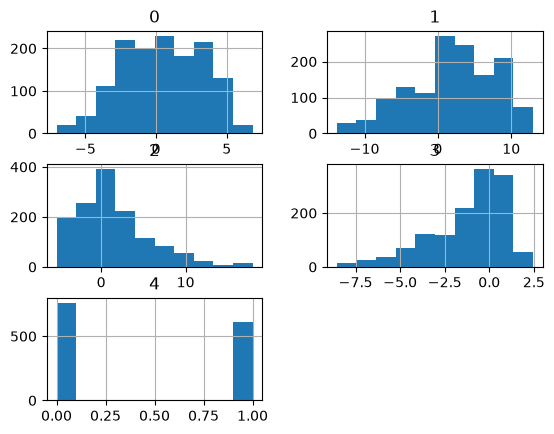

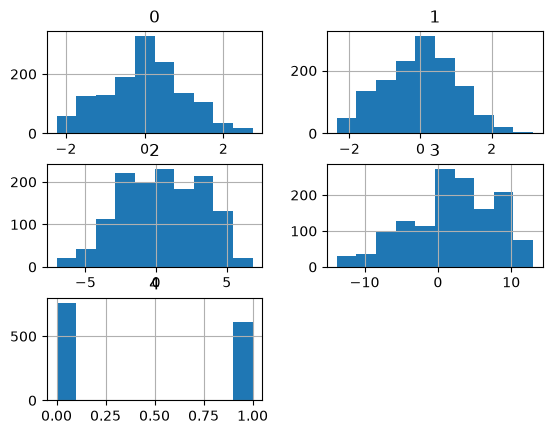

In [43]:
print("Pre", df.skew())
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method="yeo-johnson")
pre = ColumnTransformer([("pt", pt, [2, 3])], remainder="passthrough")
df_transformed = pre.fit_transform(df)


df_transformed = pd.DataFrame(df_transformed, columns=df.columns)
print("Post", df_transformed.skew())
df.hist(); df_transformed.hist()


### 2. Unsupervised Learning

Use PCA and plot the two first components colouring according with the class. Are the classes linearly separable in this projection? What happens when I applied k-means with two classes in this space? And if I use all the coordinates? Try also t-SNE for projection and DBSCAN for the clustering and comment on the results.

### 3. Supervised Learning

Generate a subset of the data of 372 elements that would be saved as test set. With the rest of the data generate the following models: Logistic Regression, Decision tree (use the ID3 algorithm), Naive Bayes and k-NN. 

Investigate the effect of regularization (when possible) and use cross validation for setting the hyper-parameters when needed. 

Compare the performances in terms of accuracy, precision, recall and F1-score on the test set. Comment these results at the light of those obtained from the Unsupervised Learning analysis. Could you propose a way to improve these results?     
